### TEST · dominio pequeño (Mediterráneo occidental, 30–48 °N, 5 °W–20 °E)
¿Concentrar las 30 PCs en la región donde se genera el oleaje mejora el XGB en extremos? Todo se guarda con el sufijo `_wmed`; el pipeline de dominio completo no se toca.

In [36]:
import os, json, pickle

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from xgboost import XGBRegressor
from sklearn.model_selection import GroupKFold
from scipy.signal import find_peaks
from utils.pit.piece_wise_marginal import from_normal

import xarray as xr

from bluemath_tk.core.io import load_model

import cartopy.crs as ccrs
import cartopy.feature as cfeature

#### Load and Prepare Data

In [37]:
point = 'p102'

#### Predictores: 30 PCs de presión + 10 PCs del gradiente reconstruido (6 h)
pcs_msl = pd.read_csv('outputs/pca/pcs_msl_30_6h_wmed.csv', index_col=0, parse_dates=True)
pcs_grad = pd.read_csv('outputs/grad_rec/pcs_grad_rec_6h_wmed.csv', index_col=0, parse_dates=True)
data_pcs = pcs_msl.join(pcs_grad)

#### Objetivo: Z (PIT + armónica, 00_PIT), media móvil de 6 h centrada, a 00/06/12/18
waves_df_z = pd.read_csv(f'outputs/marginal/z_bulk_{point}.csv', index_col=0, parse_dates=True)
waves_df_z_6h = waves_df_z.rolling('6h', center=True).mean()
waves_df_z_6h = waves_df_z_6h[waves_df_z_6h.index.hour.isin([0, 6, 12, 18])].dropna()

#### Para volver a metros
pit = pickle.load(open(f'outputs/marginal/transformacion_{point}.pkl', 'rb'))

#### Campos reales de ERA5
era5 = xr.open_zarr('data/era5_mslp_grad_1985_2026_1deg_hourly.zarr')
era5 = era5.sel(latitude=slice(48, 30), longitude=slice(-5, 20))                     # dominio pequeño
pca_msl = load_model('outputs/pca/pca_msl_wmed.pkl')

In [38]:
lags = [0, 6, 12, 18, 24, 30, 36]
X_lagged = pd.concat({f'l{l}': data_pcs.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(data_pcs.index)
X_lagged.columns = [f'{c}_l{l[1:]}' for l, c in X_lagged.columns]
X_lagged = X_lagged.dropna()

idx = X_lagged.index.intersection(waves_df_z_6h.index)
X = X_lagged.loc[idx]
y = waves_df_z_6h.loc[idx, 'VHM0']
print(X.shape)

(60992, 280)


#### XGBoost (profundidad 3)

In [39]:
xgb_params = dict(n_estimators=300, learning_rate=0.05, max_depth=3, min_child_weight=200,
                  subsample=0.8, colsample_bytree=0.8, tree_method='hist', n_jobs=-1, random_state=0)

#### CrossValidation (1985–2015, pliegues por años)

In [40]:
tr = idx < '2016-01-01'
X_tr, y_tr = X[tr], y[tr]

f_oof = pd.Series(np.nan, index=X_tr.index)
for i_fit, i_val in GroupKFold(n_splits=5).split(X_tr, y_tr, groups=X_tr.index.year):
    model = XGBRegressor(**xgb_params).fit(X_tr.iloc[i_fit], y_tr.iloc[i_fit])
    f_oof.iloc[i_val] = model.predict(X_tr.iloc[i_val])

#### Full model

In [41]:
xgb_final = XGBRegressor(**xgb_params).fit(X_tr, y_tr)
f_test = pd.Series(xgb_final.predict(X[~tr]), index=X.index[~tr])

#### Métricas

In [42]:
print(f"6-horaria OOF:  {f_oof.corr(y_tr):.3f}")
print(f"6-horaria test: {f_test.corr(y[~tr]):.3f}")
print(f"diaria OOF:     {f_oof.resample('D').mean().corr(y_tr.resample('D').mean()):.3f}")
print(f"diaria test:    {f_test.resample('D').mean().corr(y[~tr].resample('D').mean()):.3f}")

6-horaria OOF:  0.848
6-horaria test: 0.838
diaria OOF:     0.877
diaria test:    0.866


In [43]:
#### Extremos en test, en metros: pico de f (±24 h) / pico observado en temporales > q99
def hs(z):
    zz = waves_df_z.loc[z.index].copy()
    zz['VHM0'] = z.values
    z0 = pit['harm_z'].inverse_transform(zz)['VHM0'].clip(-6.36, 6.36)
    return pd.Series(pit['marg']['VHM0'].ppf(from_normal(z0).values), index=z.index)

hs_obs, hs_f = hs(y[~tr]), hs(f_test)
picos = hs_obs.index[find_peaks(hs_obs.values, height=hs_obs.quantile(0.99), distance=12)[0]]
ratio = pd.Series([hs_f.loc[t - pd.Timedelta('24h'):t + pd.Timedelta('24h')].max() / hs_obs.loc[t] for t in picos], index=picos)
top10 = hs_obs.loc[picos].nlargest(10).index

print(f"temporales test: {len(picos)} | pico f/obs: {ratio.mean():.2f} | 10 mayores: {ratio.loc[top10].mean():.2f}")
print(f"Juliette: obs {hs_obs.loc['2023-02-25':'2023-03-03'].max():.2f} m | f {hs_f.loc['2023-02-25':'2023-03-03'].max():.2f} m")

temporales test: 53 | pico f/obs: 0.82 | 10 mayores: 0.82
Juliette: obs 5.97 m | f 4.65 m


#### Figuras

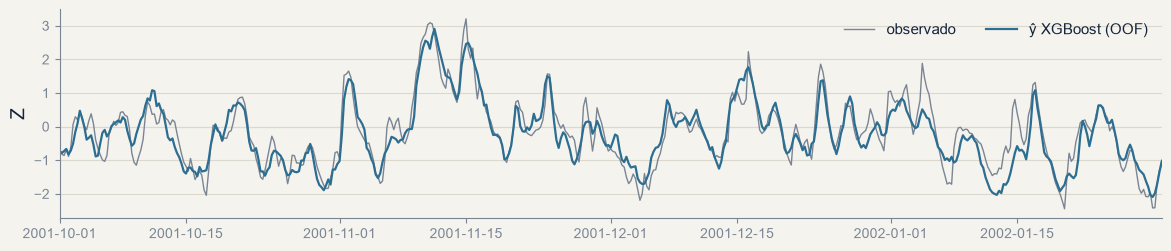

In [44]:
#### Estilo presentación
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 14, "axes.titlesize": 17, "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA,
    "xtick.color": GRIS, "ytick.color": GRIS,
})

t0, t1 = "2001-10-01", "2002-01-31"

fig, ax = plt.subplots(figsize=(11.6, 2.4), constrained_layout=True, facecolor=FONDO)
ax.plot(y.loc[t0:t1], color=GRIS, lw=1, label="observado")
ax.plot(f_oof.loc[t0:t1], color=AZUL, lw=1.6, label="ŷ XGBoost (OOF)")
ax.axhline(0, color="#DDD8CE", lw=0.8, zorder=0)
ax.set(ylabel="Z", xlim=(pd.Timestamp(t0), pd.Timestamp(t1)))
ax.set_facecolor(FONDO)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#DDD8CE", lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(labelsize=10)
ax.legend(frameon=False, loc="upper right", ncol=2, fontsize=11)

fig.savefig("figuras/wmed_xgb_serie_invierno.png", dpi=200, facecolor=FONDO)
plt.show()

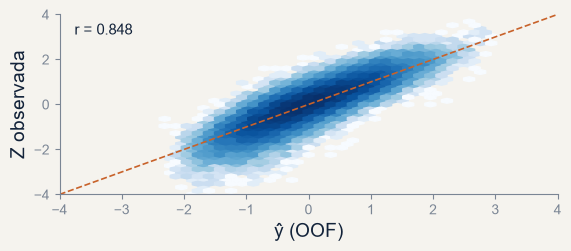

In [45]:
d = pd.concat({"z": y, "f": f_oof}, axis=1).dropna()

fig, ax = plt.subplots(figsize=(5.6, 2.4), constrained_layout=True, facecolor=FONDO)
hb = ax.hexbin(d["f"], d["z"], gridsize=45, cmap="Blues", mincnt=1, bins="log", extent=(-4, 4, -4, 4))
ax.plot([-4, 4], [-4, 4], color=NARANJA, lw=1.2, ls="--")
ax.text(0.03, 0.95, f"r = {d['z'].corr(d['f']):.3f}", transform=ax.transAxes, va="top", fontsize=11)
ax.set(xlabel="ŷ (OOF)", ylabel="Z observada", xlim=(-4, 4), ylim=(-4, 4))
ax.set_facecolor(FONDO)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(labelsize=10)

fig.savefig("figuras/wmed_xgb_dispersion.png", dpi=200, facecolor=FONDO)
plt.show()

#### Guardar

In [46]:
out_dir = f'outputs/xgb_{point}_wmed'
os.makedirs(out_dir, exist_ok=True)

#### Modelo final + orden de columnas que espera
xgb_final.save_model(f'{out_dir}/xgb_final.json')
with open(f'{out_dir}/xgb_features.json', 'w') as f:
    json.dump({'columns': list(X_tr.columns), 'lags_h': lags, 'params': xgb_params,
               'train': ['1985-01-01', '2015-12-31']}, f, indent=1)

#### Serie horaria: z, f y residuo (OOF en 1985–2015, modelo final en 2016–2025)
f_h = pd.concat([f_oof, f_test]).sort_index().resample('h').interpolate()
z_h = waves_df_z['VHM0'].reindex(f_h.index)

residuos = pd.DataFrame({'z': z_h, 'f': f_h, 'r': z_h - f_h})
residuos['periodo'] = np.where(residuos.index < '2016-01-01', 'oof', 'test')
residuos.dropna(subset=['r']).to_csv(f'{out_dir}/residuos_horarios.csv')
print(residuos.dropna().groupby('periodo')['r'].agg(['count', 'std']))

          count       std
periodo                  
oof      271728  0.540621
test      94219  0.545690


In [47]:
#### Temporales con nombre: Hs observada vs f (OOF hasta 2015, test desde 2016)
f_all = pd.concat([f_oof, f_test]).sort_index()
hs_obs_all, hs_f_all = hs(y), hs(f_all)

picos_all = hs_obs_all.index[find_peaks(hs_obs_all.values, height=hs_obs_all.quantile(0.99), distance=12)[0]]
temporales = {f"{t:%d %b %Y}": (t - pd.Timedelta("1D"), t + pd.Timedelta("1D"))
              for t in hs_obs_all.loc[picos_all].nlargest(6).index}

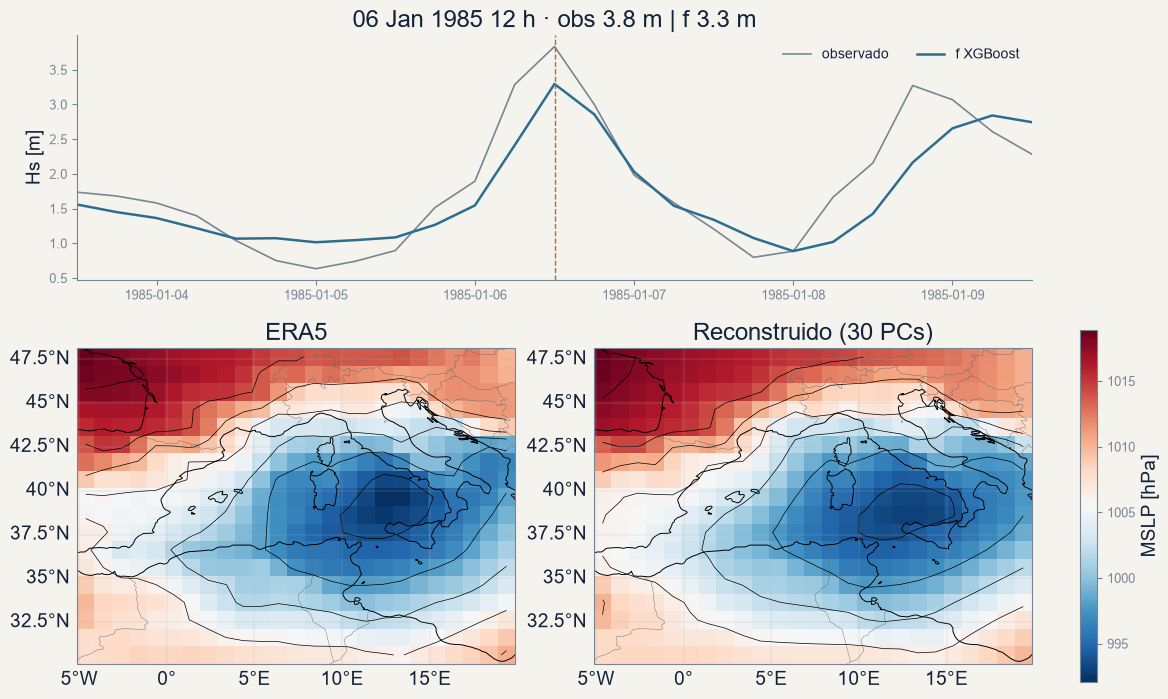

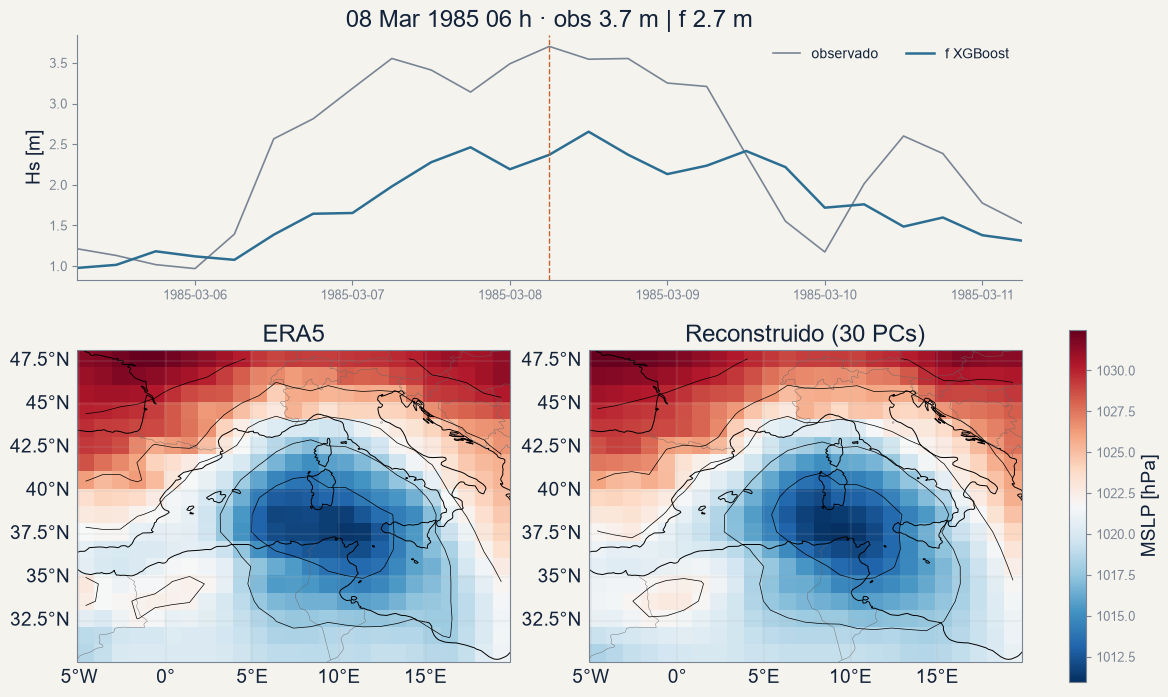

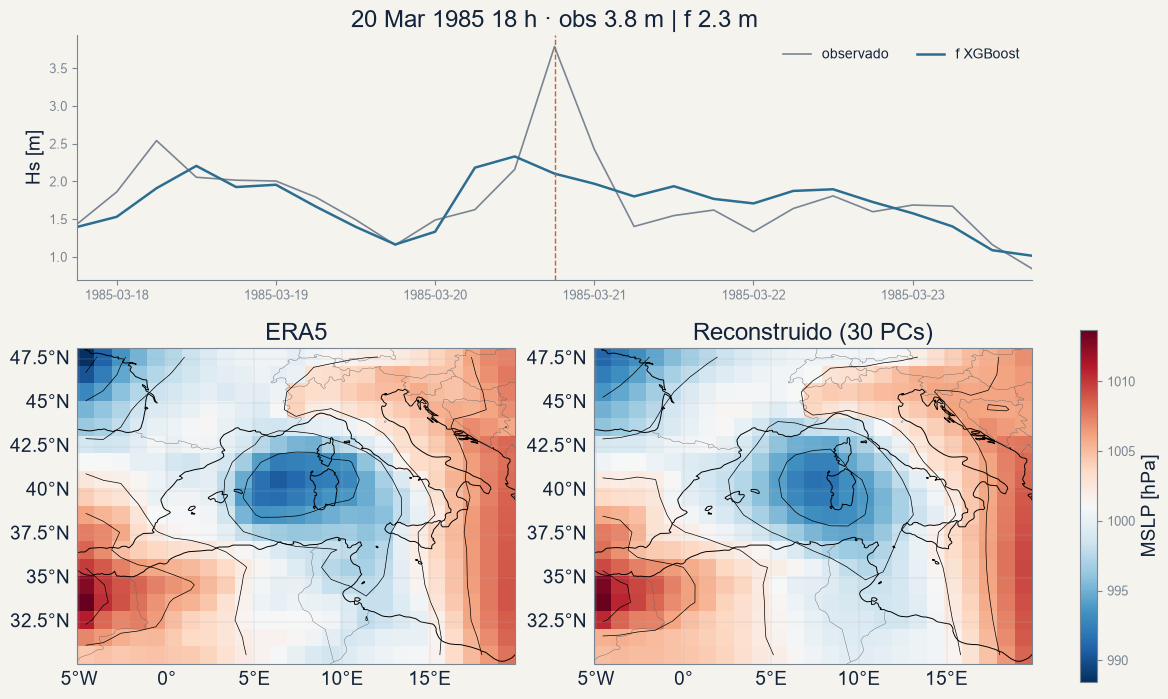

In [48]:
def format_axes(fig):
    for i, ax in enumerate(fig.axes):
        ax.text(0.5, 0.5, "ax%d" % (i+1), va="center", ha="center")
        ax.tick_params(labelbottom=False, labelleft=False)

PROJ = ccrs.PlateCarree()

for storm in picos_all[:3]:
    w0, w1 = storm - pd.Timedelta(days=3), storm + pd.Timedelta(days=3)

    #### Campo real y reconstruido con las 30 PCs en el pico (hPa)
    real = era5['msl'].sel(valid_time=storm) / 100
    pcs_da = xr.DataArray(pcs_msl.loc[[storm]].values, dims=('time', 'n_component'),
                          coords={'time': [storm], 'n_component': np.arange(pcs_msl.shape[1])})
    rec = pca_msl.inverse_transform(pcs_da)['msl'].isel(time=0) / 100
    vmin, vmax = float(min(real.min(), rec.min())), float(max(real.max(), rec.max()))

    fig = plt.figure(figsize=(11.6, 7), layout='constrained', facecolor=FONDO)
    gs = GridSpec(2, 2, figure=fig, height_ratios=[1, 1.6])
    ax1 = fig.add_subplot(gs[0, :])
    ax2 = fig.add_subplot(gs[1, 0], projection=PROJ)
    ax3 = fig.add_subplot(gs[1, 1], projection=PROJ)

    #### Serie
    ax1.plot(hs_obs_all.loc[w0:w1], color=GRIS, lw=1.2, label='observado')
    ax1.plot(hs_f_all.loc[w0:w1], color=AZUL, lw=1.8, label='f XGBoost')
    ax1.axvline(storm, color=NARANJA, lw=1, ls='--')
    ax1.set(ylabel='Hs [m]', xlim=(w0, w1),
            title=f'{storm:%d %b %Y %H h} · obs {hs_obs_all[storm]:.1f} m | f {hs_f_all.loc[w0:w1].max():.1f} m')
    ax1.legend(frameon=False, loc='upper right', ncol=2, fontsize=10)
    ax1.spines[['top', 'right']].set_visible(False)

    #### Mapas
    for ax, campo, titulo in [(ax2, real, 'ERA5'), (ax3, rec, 'Reconstruido (30 PCs)')]:
        im = campo.plot(ax=ax, transform=PROJ, cmap='RdBu_r', vmin=vmin, vmax=vmax, add_colorbar=False)
        campo.plot.contour(ax=ax, transform=PROJ, levels=np.arange(950, 1050, 4), colors='k', linewidths=0.5)
        ax.coastlines(resolution='50m', lw=0.7)
        ax.add_feature(cfeature.BORDERS, lw=0.3, color='0.4')
        gl = ax.gridlines(draw_labels=True, lw=0.3, color='0.7', alpha=0.6)
        gl.top_labels = gl.right_labels = False
        ax.set_title(titulo)
    fig.colorbar(im, ax=[ax2, ax3], label='MSLP [hPa]', shrink=0.9)

    for ax in fig.axes:
        ax.set_facecolor(FONDO)
        ax.tick_params(labelsize=9)
    plt.show()

#### ¿Sesga el PVAR la f? f con PCs simuladas vs f con PCs históricas

In [61]:
import glob, os

def f_desde(pcs_m, pcs_g):
    d = pcs_m.join(pcs_g)
    Xs = pd.concat({f'l{l}': d.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(d.index)
    Xs.columns = [f'{c}_l{l[1:]}' for l, c in Xs.columns]
    Xs = Xs.dropna()[X.columns]
    return pd.Series(xgb_final.predict(Xs), index=Xs.index)

#### Histórico 1985–2025 (modelo final, como en el emulador)
f_hist = f_desde(pcs_msl, pcs_grad).loc['1985':'2025']

#### Juegos de simulaciones a comparar (h1 = gaussiano, b = bootstrap de innovaciones)
SIMS = ['h1', 'h1b', 'h2b', 'e4b', 'm12b']

def cargar_f(sims):
    out = []
    for fm in sorted(glob.glob(f'outputs/var_6h_wmed/simulaciones_{sims}/sim_*.parquet'))[:20]:
        fg = os.path.join(f'outputs/grad_rec/simulaciones_{sims}_wmed', os.path.basename(fm).replace('sim_', 'grec_'))
        s = f_desde(pd.read_parquet(fm).astype('float64'), pd.read_parquet(fg).astype('float64'))
        a0 = s.index[0].year + 1
        out.append(s.loc[str(a0):str(a0 + 40)])                # 41 años completos
    return out

f_sims = {s: cargar_f(s) for s in SIMS}

def resumen(f):
    pk = find_peaks(f.values, height=f_hist.quantile(0.99), distance=12)[0]
    return {'q90': f.quantile(0.90), 'q99': f.quantile(0.99), 'q99.9': f.quantile(0.999),
            'máx anual medio': f.groupby(f.index.year).max().mean(),
            'picos f > q99 hist / década': len(pk) * 10 / f.index.year.nunique()}

h = pd.Series(resumen(f_hist))
tabla = pd.DataFrame({'histórico': h})
for s, lista in f_sims.items():
    tabla[f'{s} / hist'] = pd.DataFrame([resumen(f) for f in lista]).median() / h
tabla.round(3)

,histórico,h1 / hist,h1b / hist,h2b / hist,e4b / hist,m12b / hist
q90,1.059,0.901,0.901,0.897,0.888,0.891
q99,1.905,0.960,0.973,0.972,0.976,0.975
q99.9,2.525,0.965,0.996,0.997,0.997,0.997
máx anual medio,2.523,0.956,0.986,0.986,0.980,0.983
picos f > q99 hist / década,50.488,0.715,0.792,0.775,0.766,0.768


In [62]:
#### Por estación: picos de f > q99 histórico por década
est = lambda m: np.select([np.isin(m, [12, 1, 2]), np.isin(m, [3, 4, 5]), np.isin(m, [6, 7, 8])], ['invierno', 'primavera', 'verano'], 'otoño')

def picos_est(f):
    pk = f.index[find_peaks(f.values, height=f_hist.quantile(0.99), distance=12)[0]]
    return pd.Series(est(pk.month)).value_counts() * 10 / f.index.year.nunique()

tabla_est = pd.DataFrame({'histórico': picos_est(f_hist)})
for s, lista in f_sims.items():
    tabla_est[s] = pd.concat([picos_est(f) for f in lista], axis=1).fillna(0).median(axis=1)
tabla_est.loc[['invierno', 'primavera', 'verano', 'otoño']].round(1)

,histórico,h1,h1b,h2b,e4b,m12b
invierno,19.3,16.8,18.5,17.3,17.7,17.6
primavera,13.9,7.1,7.1,7.6,8.3,8.4
verano,5.9,4.9,5.7,5.6,4.9,4.8
otoño,11.5,6.7,8.2,8.3,7.8,7.8


In [51]:
f_in_hist = f_hist.loc['1985':'2015']                         # dentro de muestra (modelo final)
f_oof_hist = f_oof                                            # fuera de muestra (OOF, 1985–2015)
f_test_hist = f_hist.loc['2016':'2025']                       # fuera de muestra (modelo final, test)

display(pd.DataFrame({'dentro de muestra 1985–2015': resumen(f_in_hist),
                      'OOF 1985–2015': resumen(f_oof_hist),
                      'test 2016–2025': resumen(f_test_hist)}).round(3))

pd.DataFrame({'dentro de muestra 1985–2015': picos_est(f_in_hist),
              'OOF 1985–2015': picos_est(f_oof_hist),
              'test 2016–2025': picos_est(f_test_hist)}).loc[['invierno', 'primavera', 'verano', 'otoño']].round(1)

pd.DataFrame({'dentro de muestra 1985–2015': picos_est(f_in_hist),
              'OOF 1985–2015': picos_est(f_oof_hist),
              'test 2016–2025': picos_est(f_test_hist)}).loc[['invierno', 'primavera', 'verano', 'otoño']].round(1)

,dentro de muestra 1985–2015,OOF 1985–2015,test 2016–2025
q90,1.059,1.050,1.057
q99,1.932,1.928,1.818
q99.9,2.532,2.527,2.470
máx anual medio,2.543,2.540,2.462
picos f > q99 hist / década,53.548,51.613,41.000


,dentro de muestra 1985–2015,OOF 1985–2015,test 2016–2025
invierno,20.0,18.4,17.0
primavera,15.2,14.5,10.0
verano,5.8,6.1,6.0
otoño,12.6,12.6,8.0


In [52]:
periodos = {'1941–1978': ('1941', '1978'), '1979–2015': ('1979', '2015'), '1985–2025': ('1985', '2025'), '1941–2025': ('1941', '2025')}
f_todo = f_desde(pcs_msl, pcs_grad)

display(pd.DataFrame({p: resumen(f_todo.loc[a:b]) for p, (a, b) in periodos.items()}).round(3))
pd.DataFrame({p: picos_est(f_todo.loc[a:b]) for p, (a, b) in periodos.items()}).loc[['invierno', 'primavera', 'verano', 'otoño']].round(1)

,1941–1978,1979–2015,1985–2025,1941–2025
q90,1.036,1.061,1.059,1.050
q99,1.921,1.933,1.905,1.915
q99.9,2.462,2.527,2.525,2.496
máx anual medio,2.462,2.538,2.523,2.495
picos f > q99 hist / década,48.158,53.784,50.488,49.765


,1941–1978,1979–2015,1985–2025,1941–2025
invierno,23.2,20.5,19.3,21.3
primavera,13.4,14.3,13.9,13.4
verano,2.1,5.9,5.9,4.2
otoño,9.5,13.0,11.5,10.8


In [53]:
#### Desglose mensual: picos de f > q99 histórico por década, y cuantiles de f por mes
umbral = f_hist.quantile(0.99)
f_ref = f_todo.loc['1941':'2025']                              # periodo de ajuste del PVAR

def picos_mes(f):
    pk = f.index[find_peaks(f.values, height=umbral, distance=12)[0]]
    return pd.Series(pk.month).value_counts().reindex(range(1, 13), fill_value=0) * 10 / f.index.year.nunique()

def cuantil_mes(f, q):
    return f.groupby(f.index.month).quantile(q)

sims = f_sims['h1b']
tabla_mes = pd.DataFrame({
    'picos hist':  picos_mes(f_ref),
    'picos PVAR':  pd.concat([picos_mes(f) for f in sims], axis=1).median(axis=1),
    'q90 hist':    cuantil_mes(f_ref, 0.90),
    'q90 PVAR':    pd.concat([cuantil_mes(f, 0.90) for f in sims], axis=1).median(axis=1),
    'q99 hist':    cuantil_mes(f_ref, 0.99),
    'q99 PVAR':    pd.concat([cuantil_mes(f, 0.99) for f in sims], axis=1).median(axis=1),
})
tabla_mes['picos PVAR/hist'] = tabla_mes['picos PVAR'] / tabla_mes['picos hist']
tabla_mes['q90 PVAR−hist'] = tabla_mes['q90 PVAR'] - tabla_mes['q90 hist']
tabla_mes['q99 PVAR−hist'] = tabla_mes['q99 PVAR'] - tabla_mes['q99 hist']
tabla_mes.round(2)

,picos hist,picos PVAR,q90 hist,q90 PVAR,q99 hist,q99 PVAR,picos PVAR/hist,q90 PVAR−hist,q99 PVAR−hist
1,7.29,6.95,1.21,1.19,2.15,2.16,0.95,-0.02,0.01
2,6.00,5.37,1.20,1.15,2.07,2.04,0.89,-0.05,-0.03
3,6.00,3.78,1.17,1.02,1.99,1.88,0.63,-0.15,-0.10
4,4.59,2.32,1.14,0.95,1.93,1.75,0.51,-0.18,-0.18
5,2.82,0.98,0.90,0.79,1.76,1.52,0.35,-0.11,-0.24
6,0.94,1.71,0.82,0.78,1.56,1.60,1.81,-0.03,0.04
7,1.06,2.32,0.89,0.86,1.65,1.70,2.19,-0.03,0.06
8,2.24,2.20,0.87,0.80,1.66,1.64,0.98,-0.07,-0.01
9,1.76,1.46,0.79,0.61,1.62,1.50,0.83,-0.18,-0.12
10,4.12,2.68,0.96,0.75,1.93,1.72,0.65,-0.21,-0.22


#### Por mes: picos de f > q99 histórico por década (histórico = 1941–2025, el periodo de ajuste del PVAR)

In [54]:
f_ref = f_desde(pcs_msl, pcs_grad).loc['1941':'2025']
umbral = f_hist.quantile(0.99)

def picos_mes(f):
    pk = f.index[find_peaks(f.values, height=umbral, distance=12)[0]]
    return pd.Series(pk.month).value_counts().reindex(range(1, 13), fill_value=0) * 10 / f.index.year.nunique()

tabla_mes = pd.DataFrame({'histórico': picos_mes(f_ref)})
for s, lista in f_sims.items():
    tabla_mes[s] = pd.concat([picos_mes(f) for f in lista], axis=1).median(axis=1)
for s in f_sims:
    tabla_mes[f'{s}/hist'] = tabla_mes[s] / tabla_mes['histórico']
tabla_mes.round(2)

,histórico,h1,h1b,h2b,e4b,h1/hist,h1b/hist,h2b/hist,e4b/hist
time,,,,,,,,,
1,7.29,6.34,6.95,6.59,6.34,0.87,0.95,0.90,0.87
2,6.00,5.37,5.37,4.63,4.63,0.89,0.89,0.77,0.77
3,6.00,3.29,3.78,4.02,4.88,0.55,0.63,0.67,0.81
4,4.59,2.68,2.32,2.44,2.44,0.58,0.51,0.53,0.53
5,2.82,0.98,0.98,1.10,0.98,0.35,0.35,0.39,0.35
6,0.94,0.98,1.71,1.71,1.10,1.04,1.81,1.81,1.17
7,1.06,1.95,2.32,2.07,1.59,1.84,2.19,1.96,1.50
8,2.24,1.95,2.20,1.95,1.71,0.87,0.98,0.87,0.76
9,1.76,0.73,1.46,1.46,0.98,0.41,0.83,0.83,0.55


In [58]:
#### ¿Joint no lineal? f del XGB vs su mejor aproximación lineal, histórico vs PVAR, picos por mes
from sklearn.linear_model import Ridge

def features(pcs_m, pcs_g):
    d = pcs_m.join(pcs_g)
    Xs = pd.concat({f'l{l}': d.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(d.index)
    Xs.columns = [f'{c}_l{l[1:]}' for l, c in Xs.columns]
    return Xs.dropna()[X.columns]

#### Histórico 1941–2025: f del XGB y su imitación lineal (ajustada a f, no a las olas)
X_hist = features(pcs_msl, pcs_grad).loc['1941':'2025']
f_xgb_hist = pd.Series(xgb_final.predict(X_hist), index=X_hist.index)
lin = Ridge(alpha=1.0).fit(X_hist, f_xgb_hist)
f_lin_hist = pd.Series(lin.predict(X_hist), index=X_hist.index)
print(f'R² de la imitación lineal de f: {np.corrcoef(f_lin_hist, f_xgb_hist)[0, 1] ** 2:.3f}')

#### PVAR h1b (10 simulaciones, 41 años cada una)
f_xgb_sim, f_lin_sim = [], []
for fm in sorted(glob.glob('outputs/var_6h_wmed/simulaciones_e4b/sim_*.parquet'))[:10]:
    fg = os.path.join('outputs/grad_rec/simulaciones_e4b_wmed', os.path.basename(fm).replace('sim_', 'grec_'))
    Xs = features(pd.read_parquet(fm).astype('float64'), pd.read_parquet(fg).astype('float64'))
    a0 = Xs.index[0].year + 1
    Xs = Xs.loc[str(a0):str(a0 + 40)]
    f_xgb_sim.append(pd.Series(xgb_final.predict(Xs), index=Xs.index))
    f_lin_sim.append(pd.Series(lin.predict(Xs), index=Xs.index))

#### Picos por mes sobre el q99 histórico de cada versión
def picos_mes_u(f, u):
    pk = f.index[find_peaks(f.values, height=u, distance=12)[0]]
    return pd.Series(pk.month).value_counts().reindex(range(1, 13), fill_value=0) * 10 / f.index.year.nunique()

res = {}
for nombre, fh, fs in [('XGB', f_xgb_hist, f_xgb_sim), ('lineal', f_lin_hist, f_lin_sim)]:
    u = fh.quantile(0.99)
    h = picos_mes_u(fh, u)
    s = pd.concat([picos_mes_u(f, u) for f in fs], axis=1).median(axis=1)
    res[f'{nombre} hist'] = h
    res[f'{nombre} PVAR/hist'] = s / h
pd.DataFrame(res).round(2)

R² de la imitación lineal de f: 0.810


,XGB hist,XGB PVAR/hist,lineal hist,lineal PVAR/hist
1,7.29,0.90,7.06,0.97
2,6.00,0.75,6.12,0.82
3,5.88,0.83,5.18,1.06
4,4.24,0.52,2.71,0.77
5,2.82,0.35,1.29,0.47
6,0.94,1.17,0.00,inf
7,1.06,1.84,0.00,inf
8,2.24,0.82,0.00,NaN
9,1.76,0.48,0.00,NaN
10,4.00,0.61,1.29,0.94


In [59]:
#### Varianza y persistencia (1 día) de la f lineal por mes: histórico vs PVAR
def var_mes(f):  return f.groupby(f.index.month).std()
def acf_mes(f, l=4):
    a, b = f.values[:-l], f.values[l:]; mes = f.index.month[:-l]
    return pd.Series([np.corrcoef(a[mes == m], b[mes == m])[0, 1] for m in range(1, 13)], index=range(1, 13))

pd.DataFrame({'σ hist': var_mes(f_lin_hist),
              'σ PVAR/hist': pd.concat([var_mes(f) for f in f_lin_sim], axis=1).median(axis=1) / var_mes(f_lin_hist),
              'ACF 1 d hist': acf_mes(f_lin_hist),
              'ACF PVAR − hist': pd.concat([acf_mes(f) for f in f_lin_sim], axis=1).median(axis=1) - acf_mes(f_lin_hist)}).round(3)

,σ hist,σ PVAR/hist,ACF 1 d hist,ACF PVAR − hist
1,0.938,0.955,0.679,-0.050
2,0.912,0.897,0.678,-0.077
3,0.820,0.997,0.617,-0.016
4,0.711,0.892,0.601,0.001
5,0.586,0.870,0.624,-0.021
6,0.464,1.042,0.586,-0.025
7,0.449,0.919,0.516,0.022
8,0.445,0.930,0.554,-0.019
9,0.493,0.875,0.611,-0.020
10,0.649,0.829,0.659,-0.071


In [60]:
#### Variabilidad entre años de la media mensual de la f lineal (y de la f del XGB): histórico vs PVAR
def interanual(f):
    m = f.groupby([f.index.year, f.index.month]).mean().unstack()     # años × meses
    return m.std()

res = {}
for nombre, fh, fs in [('lineal', f_lin_hist, f_lin_sim), ('XGB', f_xgb_hist, f_xgb_sim)]:
    h = interanual(fh)
    res[f'{nombre} σ entre años hist'] = h
    res[f'{nombre} PVAR/hist'] = pd.concat([interanual(f) for f in fs], axis=1).median(axis=1) / h
pd.DataFrame(res).round(2)

,lineal σ entre años hist,lineal PVAR/hist,XGB σ entre años hist,XGB PVAR/hist
1,0.35,1.01,0.33,0.77
2,0.40,0.76,0.39,0.61
3,0.29,0.86,0.29,0.73
4,0.20,1.04,0.19,0.94
5,0.17,1.02,0.19,0.89
6,0.12,1.19,0.17,0.96
7,0.12,0.92,0.20,0.86
8,0.12,0.96,0.19,0.95
9,0.16,0.87,0.23,0.84
10,0.23,0.73,0.29,0.70


In [63]:
#### ¿El déficit viene de las PCs de presión o del gradiente reconstruido? σ por mes de cada parte de la f lineal
coef = pd.Series(lin.coef_, index=X.columns)
es_grad = X.columns.str.startswith('grec_')

def partes(Xs):
    return (pd.Series(Xs.loc[:, ~es_grad].values @ coef[~es_grad].values, index=Xs.index),
            pd.Series(Xs.loc[:, es_grad].values @ coef[es_grad].values, index=Xs.index))

p_hist, g_hist = partes(X_hist)
p_sim, g_sim = [], []
for fm in sorted(glob.glob('outputs/var_6h_wmed/simulaciones_m12b/sim_*.parquet'))[:10]:
    fg = os.path.join('outputs/grad_rec/simulaciones_m12b_wmed', os.path.basename(fm).replace('sim_', 'grec_'))
    Xs = features(pd.read_parquet(fm).astype('float64'), pd.read_parquet(fg).astype('float64'))
    a0 = Xs.index[0].year + 1
    p, g = partes(Xs.loc[str(a0):str(a0 + 40)])
    p_sim.append(p); g_sim.append(g)

sd = lambda f: f.groupby(f.index.month).std()
pd.DataFrame({'σ presión hist': sd(p_hist),
              'presión PVAR/hist': pd.concat([sd(f) for f in p_sim], axis=1).median(axis=1) / sd(p_hist),
              'σ gradiente hist': sd(g_hist),
              'gradiente PVAR/hist': pd.concat([sd(f) for f in g_sim], axis=1).median(axis=1) / sd(g_hist)}).round(3)

,σ presión hist,presión PVAR/hist,σ gradiente hist,gradiente PVAR/hist
1,0.432,1.025,0.734,0.988
2,0.437,0.991,0.682,0.993
3,0.429,0.992,0.569,1.059
4,0.386,0.999,0.491,1.001
5,0.362,0.987,0.366,1.008
6,0.319,1.025,0.271,1.132
7,0.312,0.989,0.246,1.128
8,0.308,1.004,0.238,1.059
9,0.307,1.011,0.293,0.925
10,0.344,0.978,0.461,0.916


In [64]:
corr_mes = lambda a, b: pd.Series([np.corrcoef(a[a.index.month == m], b[b.index.month == m])[0, 1] for m in range(1, 13)], index=range(1, 13))
tot_hist = p_hist + g_hist
pd.DataFrame({'corr(presión, gradiente) hist': corr_mes(p_hist, g_hist),
              'corr PVAR': pd.concat([corr_mes(p, g) for p, g in zip(p_sim, g_sim)], axis=1).median(axis=1),
              'σ total PVAR/hist': pd.concat([sd(p + g) for p, g in zip(p_sim, g_sim)], axis=1).median(axis=1) / sd(tot_hist)}).round(3)

,"corr(presión, gradiente) hist",corr PVAR,σ total PVAR/hist
1,0.243,0.064,0.936
2,0.295,0.066,0.911
3,0.335,0.025,0.903
4,0.302,0.059,0.904
5,0.296,0.104,0.915
6,0.230,0.029,0.986
7,0.290,0.090,0.976
8,0.315,0.085,0.930
9,0.348,0.110,0.883
10,0.286,0.037,0.833
